<a href="https://colab.research.google.com/github/narcelo90ff/python/blob/main/trabalhoDePython.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Conceito do GMM em linguagem simples

Imagine que os compradores tenham hábitos de compra diferentes. O GMM tenta representar esses hábitos como uma mistura de várias distribuições Gaussianas (curvas em forma de sino). Cada distribuição é chamada de **componente**.

A fórmula geral é:

\[
p(x)=\sum_{k=1}^{K}\pi_k\,\mathcal{N}(x\mid\mu_k,\Sigma_k)
\]

- **K:** quantidade de componentes que o modelo procura.
- **\(\pi_k\):** peso do componente; os pesos somam 1.
- **\(\mu_k\):** média/centro estimado do componente.
- **\(\Sigma_k\):** matriz de covariância; descreve a dispersão e as relações entre os gastos.
- **\(\mathcal{N}\):** distribuição Gaussiana (normal).

Ao contrário de uma atribuição rígida, o GMM pode dizer, por exemplo, que um cliente tem 70% de probabilidade de pertencer ao componente 1 e 30% ao componente 2. Isso é útil quando o comportamento do cliente fica entre dois perfis.

### Como o algoritmo EM aprende os componentes

1. **Inicialização:** o modelo começa com estimativas iniciais de pesos, médias e covariâncias.
2. **Etapa E (Expectation):** calcula a probabilidade/responsabilidade de cada componente para cada cliente.
3. **Etapa M (Maximization):** atualiza pesos, médias e covariâncias usando essas responsabilidades.
4. **Repetição:** alterna E e M até a melhoria ficar pequena ou atingir o limite de iterações.

O código do Scikit-learn realiza esse processo quando chamamos `modelo.fit(X_treino)`.

## 2. Bibliotecas e preparação do arquivo

**O que este bloco faz:** importa ferramentas para tabelas, cálculos, gráficos, separação treino/teste, padronização e ajuste do GMM. Também define uma semente aleatória para facilitar a reprodução do experimento.

In [14]:
# Path permite verificar se o arquivo CSV está na pasta do notebook.
from pathlib import Path

# pandas organiza os dados em tabelas (DataFrame).
import pandas as pd

# numpy fornece operações matemáticas e vetoriais.
import numpy as np

# matplotlib será usado para desenhar os gráficos.
import matplotlib.pyplot as plt

# Separa os dados em conjuntos de treinamento e teste.
from sklearn.model_selection import train_test_split

# Padroniza as variáveis para que tenham escalas comparáveis.
from sklearn.preprocessing import StandardScaler

# Implementação do modelo de Misturas Gaussianas.
from sklearn.mixture import GaussianMixture

# Métrica complementar para avaliar a separação dos grupos previstos.
from sklearn.metrics import silhouette_score

# Semente usada nas operações aleatórias para facilitar a repetição dos resultados.
RANDOM_STATE = 42

# Nome esperado do arquivo de dados.
CSV_NAME = 'Wholesale_customers_data.csv'

# No Colab, se o arquivo não estiver presente, abre a opção para enviá-lo.
if not Path(CSV_NAME).exists():
    try:
        from google.colab import files
        print('Envie o arquivo Wholesale_customers_data.csv')
        files.upload()
    except Exception:
        # Fora do Colab, essa importação não existe; o programa seguirá para a verificação abaixo.
        pass

# Interrompe com uma mensagem clara caso o CSV continue ausente.
if not Path(CSV_NAME).exists():
    raise FileNotFoundError(
        'Coloque Wholesale_customers_data.csv na pasta do notebook ou faça upload no Colab.'
    )

## 3. Leitura e exploração inicial

**O que este bloco faz:** lê a base, seleciona as seis colunas de gastos e verifica quantidade de linhas, valores ausentes, duplicatas e distribuição das colunas `Channel` e `Region`.

**Por que isso importa:** antes de treinar um modelo, precisamos conhecer o tamanho e a qualidade dos dados. `Channel` e `Region` são mostradas apenas para conhecimento e não entram na matriz de treinamento.

In [15]:
# Lê o arquivo CSV e cria uma tabela chamada df.
df = pd.read_csv(CSV_NAME)

# Lista das seis variáveis numéricas de gastos indicadas no enunciado do Grupo 4.
features = [
    'Fresh',              # gastos com produtos frescos
    'Milk',               # gastos com leite e derivados
    'Grocery',            # gastos com mercearia
    'Frozen',             # gastos com congelados
    'Detergents_Paper',   # detergentes e produtos de papel
    'Delicassen'          # delicatessen
]

# Seleciona apenas as seis variáveis que serão usadas como entrada do GMM.
spending = df[features].astype(float)

# Exibe informações para entender a base antes do tratamento.
print('Dimensão da base (linhas, colunas):', df.shape)
print('Quantidade de clientes:', len(df))
print('Valores ausentes na base:', int(df.isna().sum().sum()))
print('Linhas duplicadas:', int(df.duplicated().sum()))
print('Distribuição de Channel (somente consulta):')
print(df['Channel'].value_counts().sort_index())
print('Distribuição de Region (somente consulta):')
print(df['Region'].value_counts().sort_index())

# Confere se é a versão esperada da base, com 440 clientes.
assert len(df) == 440, 'A base esperada tem 440 linhas. Confira o arquivo utilizado.'

# Confere se as variáveis usadas no GMM não possuem valores ausentes.
assert spending.isna().sum().sum() == 0, 'Há valores ausentes nas categorias de gasto.'

Dimensão da base (linhas, colunas): (440, 8)
Quantidade de clientes: 440
Valores ausentes na base: 0
Linhas duplicadas: 0
Distribuição de Channel (somente consulta):
Channel
1    298
2    142
Name: count, dtype: int64
Distribuição de Region (somente consulta):
Region
1     77
2     47
3    316
Name: count, dtype: int64


## 4. Pré-processamento: logaritmo, divisão e padronização

Os gastos possuem escalas diferentes e podem apresentar forte assimetria (alguns clientes gastam muito mais que a maioria).




Formato do treino: (352, 6)
Formato do teste: (88, 6)


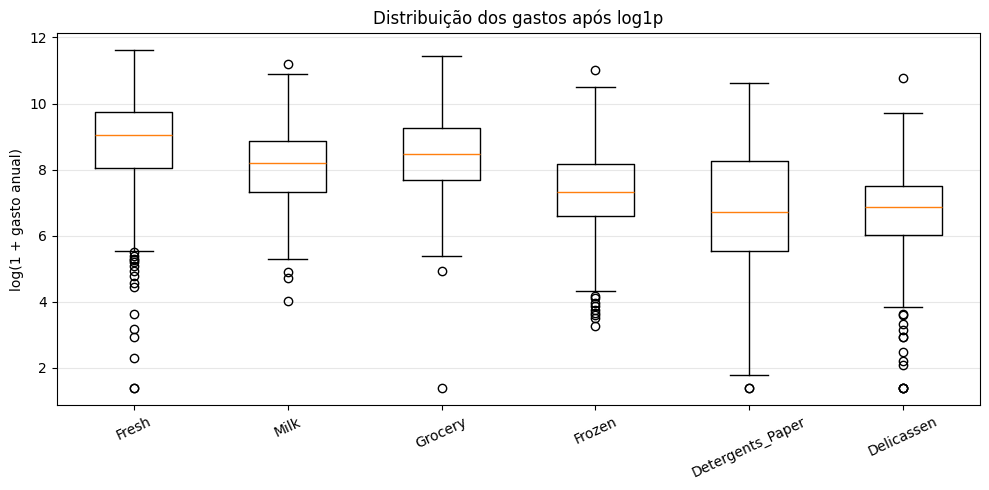

In [16]:
# Aplica log(1 + gasto) a cada valor, diminuindo a assimetria da distribuição.
X_log = np.log1p(spending)

# Separa 20% dos clientes para teste e mantém 80% no treino.
X_train_raw, X_test_raw = train_test_split(
    X_log,
    test_size=0.20,
    random_state=RANDOM_STATE
)

# Cria o objeto que vai calcular médias e desvios das variáveis do treino.
scaler = StandardScaler()

# Aprende os parâmetros no treino e padroniza o próprio treino.
X_train = scaler.fit_transform(X_train_raw)

# Padroniza o teste com os parâmetros aprendidos no treino (sem recalcular médias).
X_test = scaler.transform(X_test_raw)

# Mostra quantas linhas e variáveis existem em cada parte.
print('Formato do treino:', X_train.shape)
print('Formato do teste:', X_test.shape)

# Desenha boxplots para comparar a distribuição dos gastos depois de log1p.
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot([X_log[c] for c in features])
# Rótulos à parte: funciona em qualquer versão do matplotlib (tick_labels exige a 3.9+).
ax.set_xticklabels(features)
ax.set_title('Distribuição dos gastos após log1p')
ax.set_ylabel('log(1 + gasto anual)')
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.3)
plt.tight_layout()
plt.show()

### Assimetria e correlações

O enunciado pede explorar assimetria e correlações. A tabela mostra que o `log1p` reduz muito a assimetria. As correlações são mostradas antes e depois da transformação: Milk–Grocery vai de 0,73 para 0,76 e Grocery–Detergents_Paper de 0,92 para 0,80.

Assimetria antes e depois do log1p:


,bruto,log1p
Fresh,2.56,-1.58
Milk,4.05,-0.22
Grocery,3.59,-0.67
Frozen,5.91,-0.35
Detergents_Paper,3.63,-0.24
Delicassen,11.15,-1.09


Milk-Grocery: bruta = 0.73 | após log1p = 0.76
Grocery-Detergents_Paper: bruta = 0.92 | após log1p = 0.8


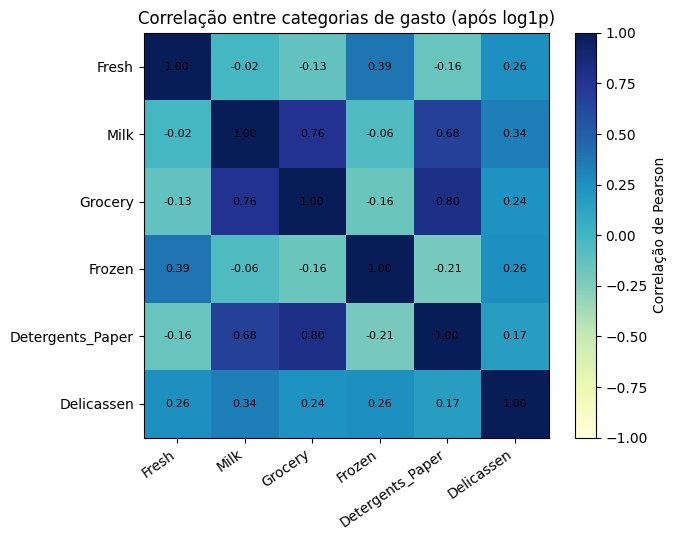

In [17]:
# Assimetria (skew) antes e depois do log1p.
print('Assimetria antes e depois do log1p:')
display(pd.DataFrame({'bruto': spending.skew(), 'log1p': X_log.skew()}).round(2))

# Correlações antes e depois da transformação.
corr_raw = spending.corr()
corr_log = X_log.corr()
print('Milk-Grocery: bruta =', round(corr_raw.loc['Milk', 'Grocery'], 2), '| após log1p =', round(corr_log.loc['Milk', 'Grocery'], 2))
print('Grocery-Detergents_Paper: bruta =', round(corr_raw.loc['Grocery', 'Detergents_Paper'], 2), '| após log1p =', round(corr_log.loc['Grocery', 'Detergents_Paper'], 2))

# Mapa de calor das correlações após log1p.
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(corr_log.values, cmap='YlGnBu', vmin=-1, vmax=1)
ax.set_xticks(range(6), features, rotation=35, ha='right')
ax.set_yticks(range(6), features)
for a in range(6):
    for b in range(6):
        ax.text(b, a, f'{corr_log.values[a, b]:.2f}', ha='center', va='center', fontsize=8)
ax.set_title('Correlação entre categorias de gasto (após log1p)')
fig.colorbar(im, ax=ax, label='Correlação de Pearson')
plt.tight_layout()
plt.show()

## 5. Configurações que serão comparadas

O enunciado pede comparar diferentes quantidades de componentes e estruturas de covariância. Aqui serão testados:

- **K = 1, 2, 3, 4, 5 e 6:** número de componentes gaussianos;
- **full:** cada componente tem sua própria matriz de covariância completa;
- **tied:** todos os componentes compartilham uma única matriz completa;
- **diag:** cada componente tem variâncias próprias, mas sem covariâncias entre variáveis;
- **spherical:** cada componente tem uma única variância para todas as dimensões.

São 6 × 4 = **24 configurações**.

### Métricas da comparação

- **BIC:** combina qualidade do ajuste e penalização da quantidade de parâmetros. Menor valor é preferível.
- **AIC:** também considera o ajuste e penaliza a complexidade, com penalização diferente. Menor é preferível.
- **Log-verossimilhança média no teste:** mede quanto o modelo atribui densidade aos dados reservados. Maior (ou menos negativa) é preferível.

Não é obrigatório que as três métricas escolham a mesma configuração. A divergência deve ser discutida, e não escondida.

Melhor BIC:


,n_components,covariance_type,BIC,AIC,test_log_likelihood_mean,converged,iterations
2,3,full,5130.225538,4809.544151,-7.487196,True,9


Melhor AIC:


,n_components,covariance_type,BIC,AIC,test_log_likelihood_mean,converged,iterations
5,6,full,5354.516733,4709.290327,-8.05384,True,28


Melhor log-verossimilhança média no teste:


,n_components,covariance_type,BIC,AIC,test_log_likelihood_mean,converged,iterations
3,4,full,5177.059228,4748.196167,-7.397166,True,26


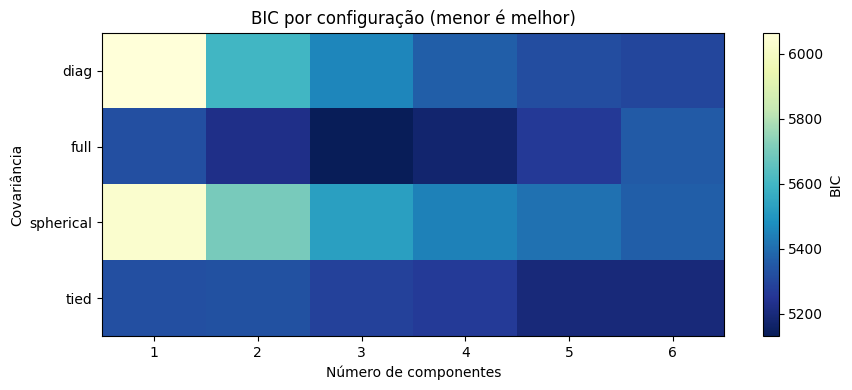

In [18]:
# Lista que vai receber os resultados das 24 configurações.
results = []

# Testa quatro formas de representar a covariância dos componentes.
for covariance in ['full', 'tied', 'diag', 'spherical']:

    # Para cada covariância, testa de 1 até 6 componentes gaussianos.
    for k in range(1, 7):

        # Cria o modelo com a combinação atual de parâmetros.
        gm = GaussianMixture(
            n_components=k,              # quantidade de componentes gaussianos
            covariance_type=covariance,  # formato da matriz de covariância
            random_state=RANDOM_STATE,   # controla a aleatoriedade
            n_init=10,                   # tenta 10 inicializações diferentes
            reg_covar=1e-5,              # regularização para estabilidade numérica
            max_iter=1000                # limite máximo de iterações do algoritmo EM
        )

        # Treina o GMM com os dados de treinamento.
        gm.fit(X_train)

        # Guarda métricas e informações sobre a execução do modelo.
        results.append({
            'n_components': k,
            'covariance_type': covariance,
            'BIC': gm.bic(X_train),
            'AIC': gm.aic(X_train),
            'test_log_likelihood_mean': gm.score(X_test),
            'converged': gm.converged_,
            'iterations': gm.n_iter_
        })

# Transforma a lista de resultados em uma tabela do pandas.
results = pd.DataFrame(results)

# Salva a comparação para abrir no Excel ou anexar ao trabalho.
results.to_csv('comparacao_modelos.csv', index=False)

# Localiza a linha com menor BIC: idxmin retorna o índice do menor valor.
print('Melhor BIC:')
display(results.loc[[results['BIC'].idxmin()]])

# Localiza a linha com menor AIC.
print('Melhor AIC:')
display(results.loc[[results['AIC'].idxmin()]])

# Localiza a linha com maior log-verossimilhança média no teste.
print('Melhor log-verossimilhança média no teste:')
display(results.loc[[results['test_log_likelihood_mean'].idxmax()]])

# Reorganiza os valores de BIC para facilitar a construção do mapa de calor.
bic_pivot = results.pivot(
    index='covariance_type',
    columns='n_components',
    values='BIC'
)

# Exibe o mapa de calor: células com BIC menor representam melhor equilíbrio segundo essa métrica.
fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(bic_pivot.values, aspect='auto', cmap='YlGnBu_r')
ax.set_xticks(range(6), range(1, 7))
ax.set_yticks(range(4), bic_pivot.index)
ax.set_xlabel('Número de componentes')
ax.set_ylabel('Covariância')
ax.set_title('BIC por configuração (menor é melhor)')
fig.colorbar(im, ax=ax, label='BIC')
plt.tight_layout()
plt.show()

### Curvas de BIC, AIC e log-verossimilhança de teste

O BIC e o AIC são calculados no treino. A log-verossimilhança é calculada no teste. Repare que, com K=6 (escolha do AIC), a log-verossimilhança de teste **piora**: isso indica superajuste. O teste melhora até K=4 e depois cai.

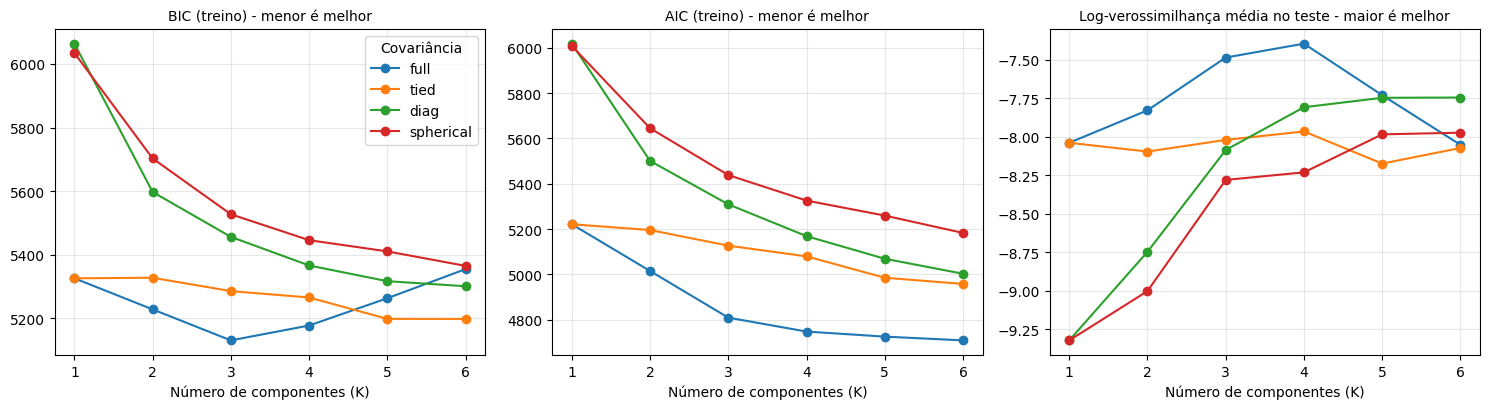

In [19]:
# Curvas dos três critérios em função de K, uma linha para cada tipo de covariância.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for covariance in ['full', 'tied', 'diag', 'spherical']:
    part = results[results['covariance_type'] == covariance]
    axes[0].plot(part['n_components'], part['BIC'], marker='o', label=covariance)
    axes[1].plot(part['n_components'], part['AIC'], marker='o', label=covariance)
    axes[2].plot(part['n_components'], part['test_log_likelihood_mean'], marker='o', label=covariance)
for ax, title in zip(axes, ['BIC (treino) - menor é melhor', 'AIC (treino) - menor é melhor', 'Log-verossimilhança média no teste - maior é melhor']):
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('Número de componentes (K)')
    ax.grid(alpha=.3)
axes[0].legend(title='Covariância')
plt.tight_layout()
plt.show()

## 6. Escolha do modelo e ajuste final

Neste experimento, a configuração principal é escolhida pelo **menor BIC** no conjunto de treinamento. A decisão privilegia um equilíbrio entre ajuste e complexidade.

Depois da comparação, o modelo selecionado é ajustado novamente usando todos os 440 clientes para descrever os perfis da base completa. Essa segunda etapa é descritiva: as métricas de comparação anteriores continuam sendo as referências para a seleção.

In [20]:
# Seleciona a linha da tabela que possui o menor BIC.
best_bic = results.loc[results['BIC'].idxmin()]

# Converte a quantidade de componentes para inteiro e guarda a covariância escolhida.
selected_k = int(best_bic['n_components'])
selected_cov = str(best_bic['covariance_type'])
print('Configuração selecionada pelo BIC:', selected_k, selected_cov)

# Cria um novo padronizador para preparar a base completa para a análise descritiva final.
scaler_all = StandardScaler()

# Ajusta o padronizador em todos os dados transformados por log1p.
X_all = scaler_all.fit_transform(X_log)

# Cria o modelo final com os parâmetros escolhidos na comparação.
final_model = GaussianMixture(
    n_components=selected_k,          # quantidade de componentes escolhida pelo BIC
    covariance_type=selected_cov,     # estrutura de covariância escolhida pelo BIC
    random_state=RANDOM_STATE,
    n_init=20,                        # usa mais inicializações no ajuste final
    reg_covar=1e-5,
    max_iter=1000
)

# Ajusta os parâmetros finais (pesos, médias e covariâncias) aos 440 clientes.
final_model.fit(X_all)

# predict escolhe, para cada cliente, o componente com maior probabilidade posterior.
labels = final_model.predict(X_all)

# predict_proba retorna a probabilidade de cada cliente pertencer a cada componente.
# Cada linha soma aproximadamente 1; assim é possível observar casos ambíguos.
probabilities = final_model.predict_proba(X_all)

# Copia os dados originais e adiciona a identificação do componente mais provável.
result_df = df.copy()
result_df['cluster'] = labels

# Salva a base com a coluna de componente para análise posterior.
result_df.to_csv('clientes_com_cluster.csv', index=False)

Configuração selecionada pelo BIC: 3 full


## 7. Métricas, tamanhos dos componentes e probabilidades



Tamanho dos componentes:


,clientes
cluster,
0,61
1,222
2,157


Pesos da mistura: [0.1586 0.4939 0.3475]
BIC no ajuste final: 6268.32
AIC no ajuste final: 5929.12
Log-verossimilhança média: -6.549
Silhouette complementar: 0.242
Probabilidade máxima média: 93.1 %
Clientes com probabilidade máxima < 0,70: 6.4 %


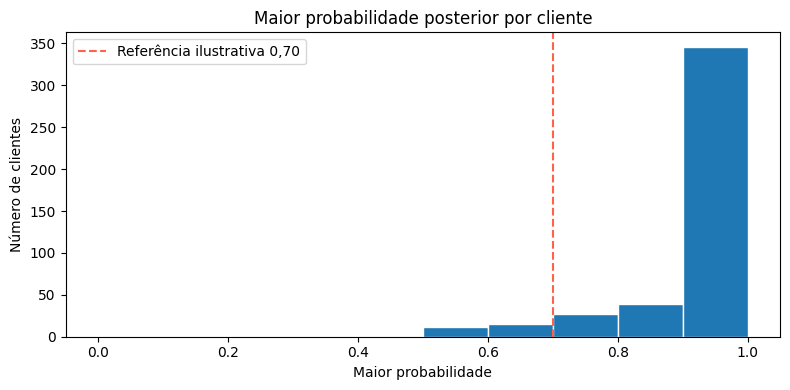

Cliente 177: componente previsto=1, probabilidades=[0.339 0.368 0.293]
Cliente 275: componente previsto=1, probabilidades=[0.201 0.503 0.296]
Cliente 344: componente previsto=2, probabilidades=[0.491 0.    0.509]
Cliente 31: componente previsto=1, probabilidades=[0.026 0.518 0.456]
Cliente 179: componente previsto=0, probabilidades=[0.529 0.471 0.   ]


In [21]:
# Conta quantos clientes foram associados ao componente 0, 1, 2 etc.
print('Tamanho dos componentes:')
display(result_df['cluster'].value_counts().sort_index().rename('clientes').to_frame())

# Mostra os pesos estimados dos componentes (proporções que somam aproximadamente 1).
print('Pesos da mistura:', np.round(final_model.weights_, 4))

# Calcula BIC e AIC do ajuste final sobre todos os clientes.
print('BIC no ajuste final:', round(final_model.bic(X_all), 2))
print('AIC no ajuste final:', round(final_model.aic(X_all), 2))

# Calcula a log-verossimilhança média por observação no conjunto completo.
print('Log-verossimilhança média:', round(final_model.score(X_all), 4))

# Silhouette só pode ser calculado quando há pelo menos dois rótulos de componente.
if len(np.unique(labels)) > 1:
    print('Silhouette complementar:', round(silhouette_score(X_all, labels), 4))
else:
    print('Silhouette não calculado: foi encontrado apenas um componente.')

# Extrai a maior probabilidade para cada cliente.
max_probability = probabilities.max(axis=1)
print('Probabilidade máxima média:', round(max_probability.mean() * 100, 1), '%')
print('Clientes com probabilidade máxima < 0,70:', round((max_probability < .70).mean() * 100, 1), '%')

# Histograma mostra quantos clientes têm probabilidade máxima em cada faixa.
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(max_probability, bins=np.linspace(0, 1, 11), edgecolor='white')
ax.axvline(.70, color='tomato', linestyle='--', label='Referência ilustrativa 0,70')
ax.set_title('Maior probabilidade posterior por cliente')
ax.set_xlabel('Maior probabilidade')
ax.set_ylabel('Número de clientes')
ax.legend()
plt.tight_layout()
plt.show()

# Exibe os cinco clientes com menor probabilidade máxima, isto é, os casos mais ambíguos.
ambiguous = np.argsort(max_probability)[:5]
for idx in ambiguous:
    print(
        f'Cliente {idx + 1}: componente previsto={labels[idx]}, '
        f'probabilidades={np.round(probabilities[idx], 3)}'
    )

## 8. Interpretação dos perfis de compradores

Os números 0, 1 e 2 (ou outros, conforme a execução) são apenas identificadores técnicos dos componentes. Eles não têm uma ordem de qualidade e podem trocar de posição em outra versão do scikit-learn ou em outra máquina: identifique cada componente pelo perfil de gastos, não pelo número.

Para interpretar cada grupo, observamos as medianas e as médias de gastos nas seis categorias. A **mediana** é importante porque valores extremos podem puxar a média para cima.

As tabelas cruzadas de `Channel` e `Region` são análises posteriores: servem para descrever como os componentes se distribuem nessas colunas, mas elas não participaram do treinamento.

Medianas por componente:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
cluster,,,,,,
0,2438.0,2713.0,4710.0,915.0,290.0,259.0
1,10724.5,1991.5,2466.5,2511.5,355.5,914.5
2,5626.0,7639.0,11532.0,993.0,4973.0,1371.0


Médias por componente:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
cluster,,,,,,
0,9287.4,4614.1,7583.0,2506.7,1869.4,1687.6
1,14584.3,2972.4,3244.7,4315.9,519.4,1261.1
2,9400.5,10248.6,14749.5,1532.6,6614.7,1834.6


Distribuição posterior por canal:


Channel,1,2
cluster,,
0,0.852,0.148
1,0.968,0.032
2,0.197,0.803


Distribuição posterior por região:


Region,1,2,3
cluster,,,
0,0.148,0.131,0.721
1,0.212,0.104,0.685
2,0.134,0.102,0.764


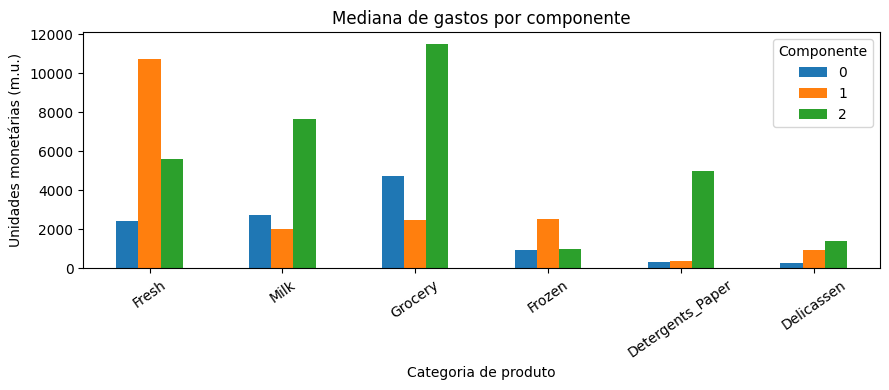

In [22]:
# Lista novamente as seis variáveis usadas no modelo, para deixar clara a tabela de perfis.
features = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']

# Calcula a mediana dos gastos dentro de cada componente.
profile_median = result_df.groupby('cluster')[features].median().round(1)

# Calcula também a média, para permitir comparação com a mediana.
profile_mean = result_df.groupby('cluster')[features].mean().round(1)

print('Medianas por componente:')
display(profile_median)
print('Médias por componente:')
display(profile_mean)

# Analisa Channel depois do treinamento; normalize='index' transforma as contagens em proporções por componente.
print('Distribuição posterior por canal:')
display(pd.crosstab(result_df['cluster'], result_df['Channel'], normalize='index').round(3))

# Analisa Region depois do treinamento, também em proporções por componente.
print('Distribuição posterior por região:')
display(pd.crosstab(result_df['cluster'], result_df['Region'], normalize='index').round(3))

# Cria um gráfico para comparar a mediana das seis categorias nos componentes.
fig, ax = plt.subplots(figsize=(9, 4))
profile_median.T.plot(kind='bar', ax=ax)
ax.set_title('Mediana de gastos por componente')
ax.set_ylabel('Unidades monetárias (m.u.)')
ax.set_xlabel('Categoria de produto')
ax.legend(title='Componente')
ax.tick_params(axis='x', rotation=35)
plt.tight_layout()
plt.show()